In [1]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

root = '/Users/samsonkoelle/isometry-pursuit'

with open(f'{root}/results/ethanol_results.json') as f:
    results = json.load(f)

with open(f'{root}/data/ethanol_metadata.json') as f:
    meta = json.load(f)

replicates_df = pd.DataFrame(results['replicates'])
selected_points = np.array(meta['selected_points'])
angles = np.load(f'{root}/{meta["angles_file"]}')

replicates_df.head()

,replicate,support_cardinality,group_lasso_norm,basis_pursuit_iterations,basis_pursuit_indices,greedy_gl_indices,greedy_gl_norm,greedy_gl_bp_indices,greedy_gl_bp_norm
0,0,3,2.250439,100000,"[103, 151, 403]","[403, 151]",2.444063,"[403, 151]",2.444063
1,1,2,2.112904,100000,"[79, 602]","[602, 79]",2.112904,"[602, 79]",2.112904
2,2,3,2.283383,100000,"[13, 175, 403]","[175, 103]",2.325017,"[175, 403]",2.456986
3,3,3,2.360157,100000,"[13, 103, 653]","[193, 13]",2.473102,"[653, 103]",2.289944
4,4,3,3.706905,100000,"[73, 253, 601]","[211, 73]",3.833276,"[601, 73]",3.648961


In [2]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

root = '/Users/samsonkoelle/isometry-pursuit'

with open(f'{root}/results/ethanol_results.json') as f:
    results = json.load(f)

with open(f'{root}/data/ethanol_metadata.json') as f:
    meta = json.load(f)

replicates_df = pd.DataFrame(results['replicates'])
selected_points = np.array(meta['selected_points'])
angles = np.load(f'{root}/{meta["angles_file"]}')

replicates_df.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,replicate,support_cardinality,group_lasso_norm,basis_pursuit_iterations,basis_pursuit_indices,greedy_gl_indices,greedy_gl_norm,greedy_gl_bp_indices,greedy_gl_bp_norm
0,0,3,2.250439,100000,"[103, 151, 403]","[403, 151]",2.444063,"[403, 151]",2.444063
1,1,2,2.112904,100000,"[79, 602]","[602, 79]",2.112904,"[602, 79]",2.112904
2,2,3,2.283383,100000,"[13, 175, 403]","[175, 103]",2.325017,"[175, 403]",2.456986
3,3,3,2.360157,100000,"[13, 103, 653]","[193, 13]",2.473102,"[653, 103]",2.289944
4,4,3,3.706905,100000,"[73, 253, 601]","[211, 73]",3.833276,"[601, 73]",3.648961


In [12]:
replicates_df.columns

Index(['replicate', 'support_cardinality', 'group_lasso_norm',
       'basis_pursuit_iterations', 'basis_pursuit_indices',
       'greedy_gl_indices', 'greedy_gl_norm', 'greedy_gl_bp_indices',
       'greedy_gl_bp_norm'],
      dtype='object')

KeyError: 'isometry_loss'

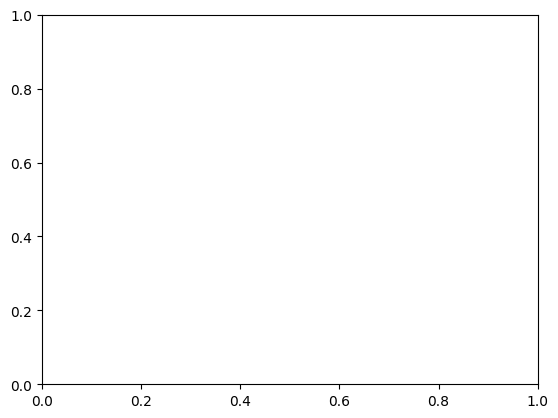

In [4]:
fig, ax = plt.subplots()
ax.scatter(replicates_df['isometry_loss'], replicates_df['group_lasso_norm'])
ax.set_xlabel('isometry_loss')
ax.set_ylabel('group_lasso_norm')
plt.show()

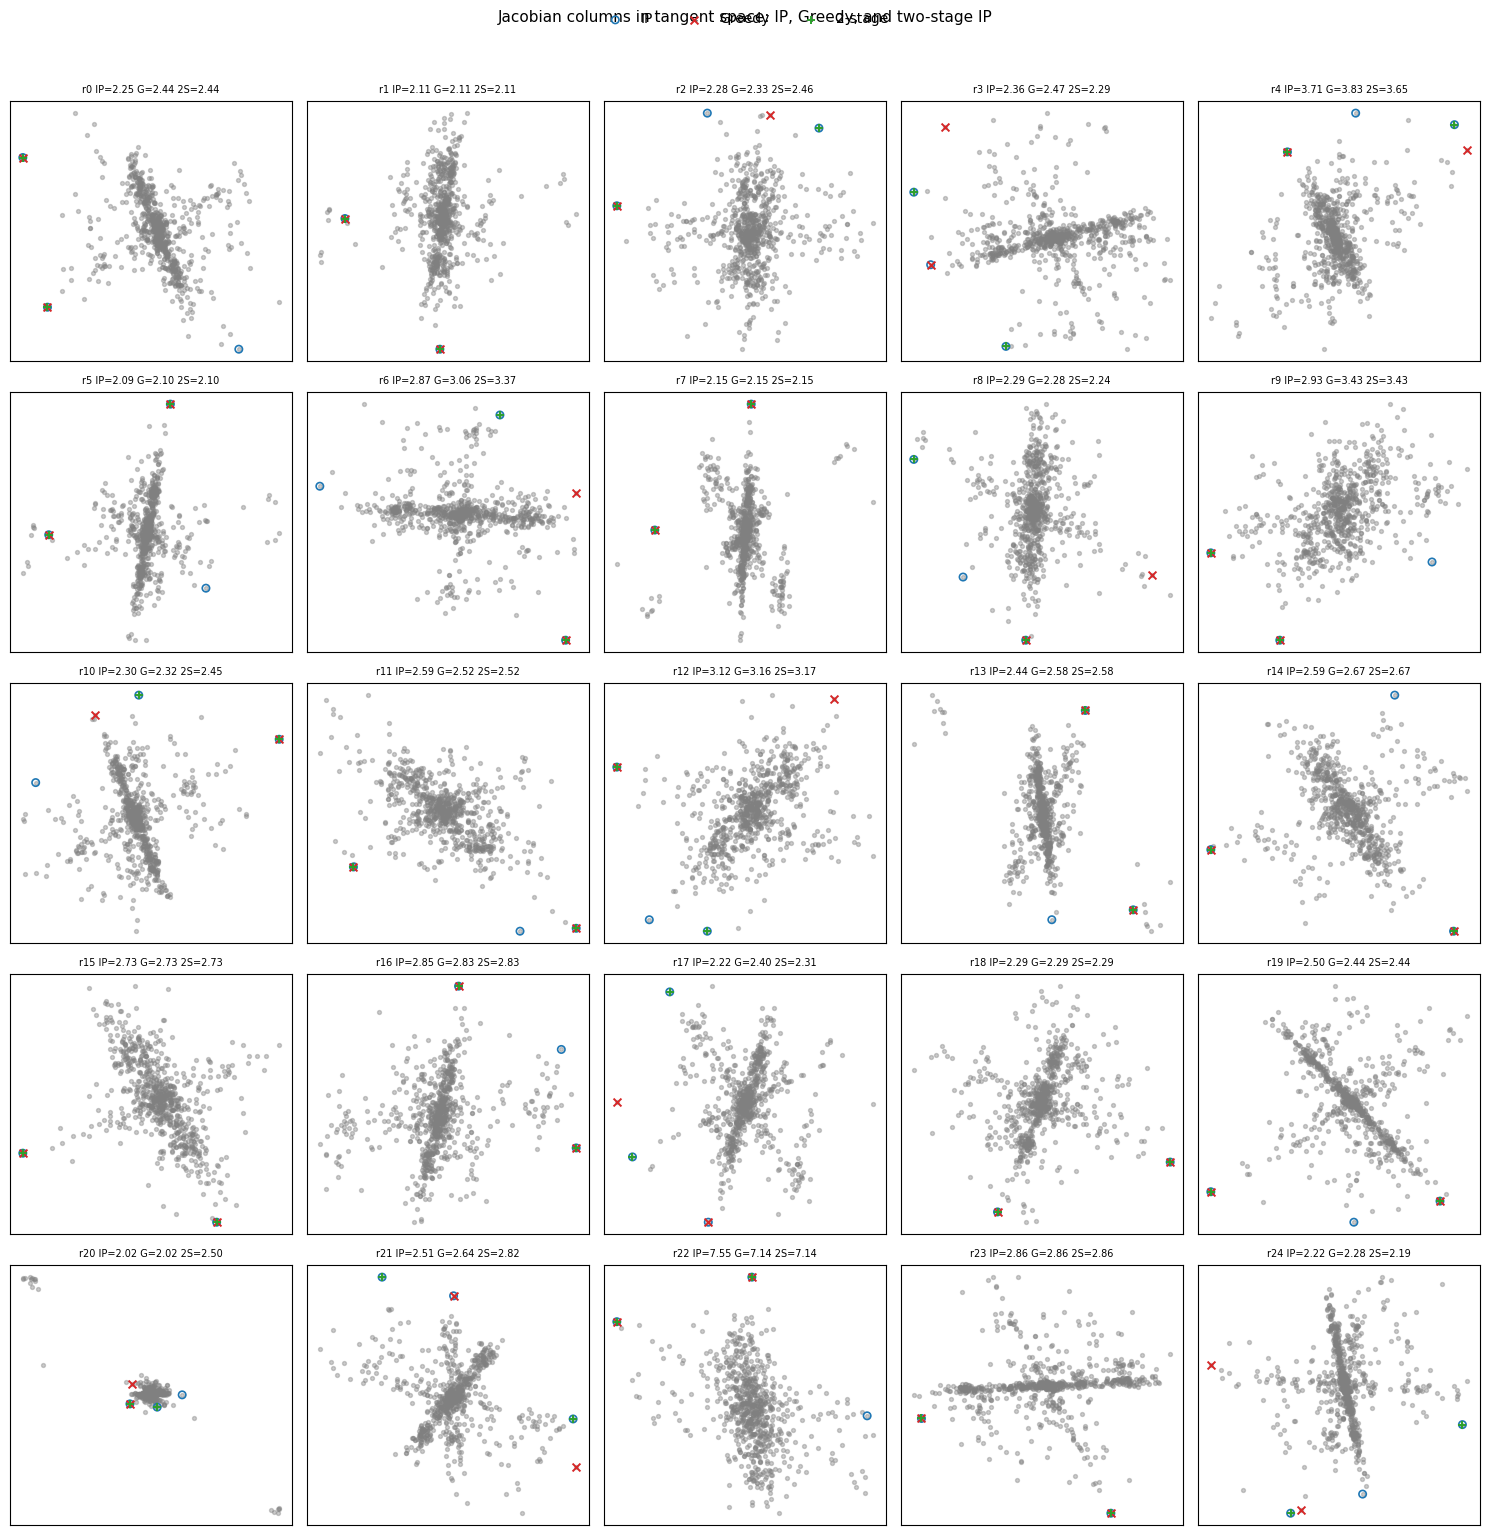

In [30]:
import numpy as np
import matplotlib.pyplot as plt

data_tensor = np.load('/Users/samsonkoelle/isometry-pursuit/data/ethanol_tensor.npy')  # (2, p, R)
R = data_tensor.shape[2]

ip_losses = replicates_df['group_lasso_norm'].values
greedy_losses = replicates_df['greedy_gl_norm'].values
two_stage_losses = replicates_df['greedy_gl_bp_norm'].values

ip_indices = replicates_df['basis_pursuit_indices'].tolist()
greedy_indices = replicates_df['greedy_gl_indices'].tolist()
two_stage_indices = replicates_df['greedy_gl_bp_indices'].tolist()

ncols = 5
nrows = (R + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = axes.flatten()

for i in range(R):
    ax = axes[i]
    cols = data_tensor[:, :, i]  # (2, p)

    ax.scatter(
        cols[0, :],
        cols[1, :],
        s=8,
        alpha=0.4,
        color='gray',
        label='other',
    )

    ax.scatter(
        cols[0, ip_indices[i]],
        cols[1, ip_indices[i]],
        s=28,
        facecolors='none',
        edgecolors='tab:blue',
        linewidths=1.2,
        label='IP',
    )

    ax.scatter(
        cols[0, greedy_indices[i]],
        cols[1, greedy_indices[i]],
        s=32,
        marker='x',
        color='tab:red',
        linewidths=1.4,
        label='Greedy',
    )

    ax.scatter(
        cols[0, two_stage_indices[i]],
        cols[1, two_stage_indices[i]],
        s=36,
        marker='+',
        color='tab:green',
        linewidths=1.4,
        label='2-stage',
    )

    ax.set_title(
        f"r{i} IP={ip_losses[i]:.2f} G={greedy_losses[i]:.2f} 2S={two_stage_losses[i]:.2f}",
        fontsize=7,
    )
    ax.set_xticks([])
    ax.set_yticks([])

for i in range(R, len(axes)):
    axes[i].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[1:], labels[1:], loc='upper center', ncol=3, frameon=False)

plt.suptitle('Jacobian columns in tangent space: IP, Greedy, and two-stage IP', fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

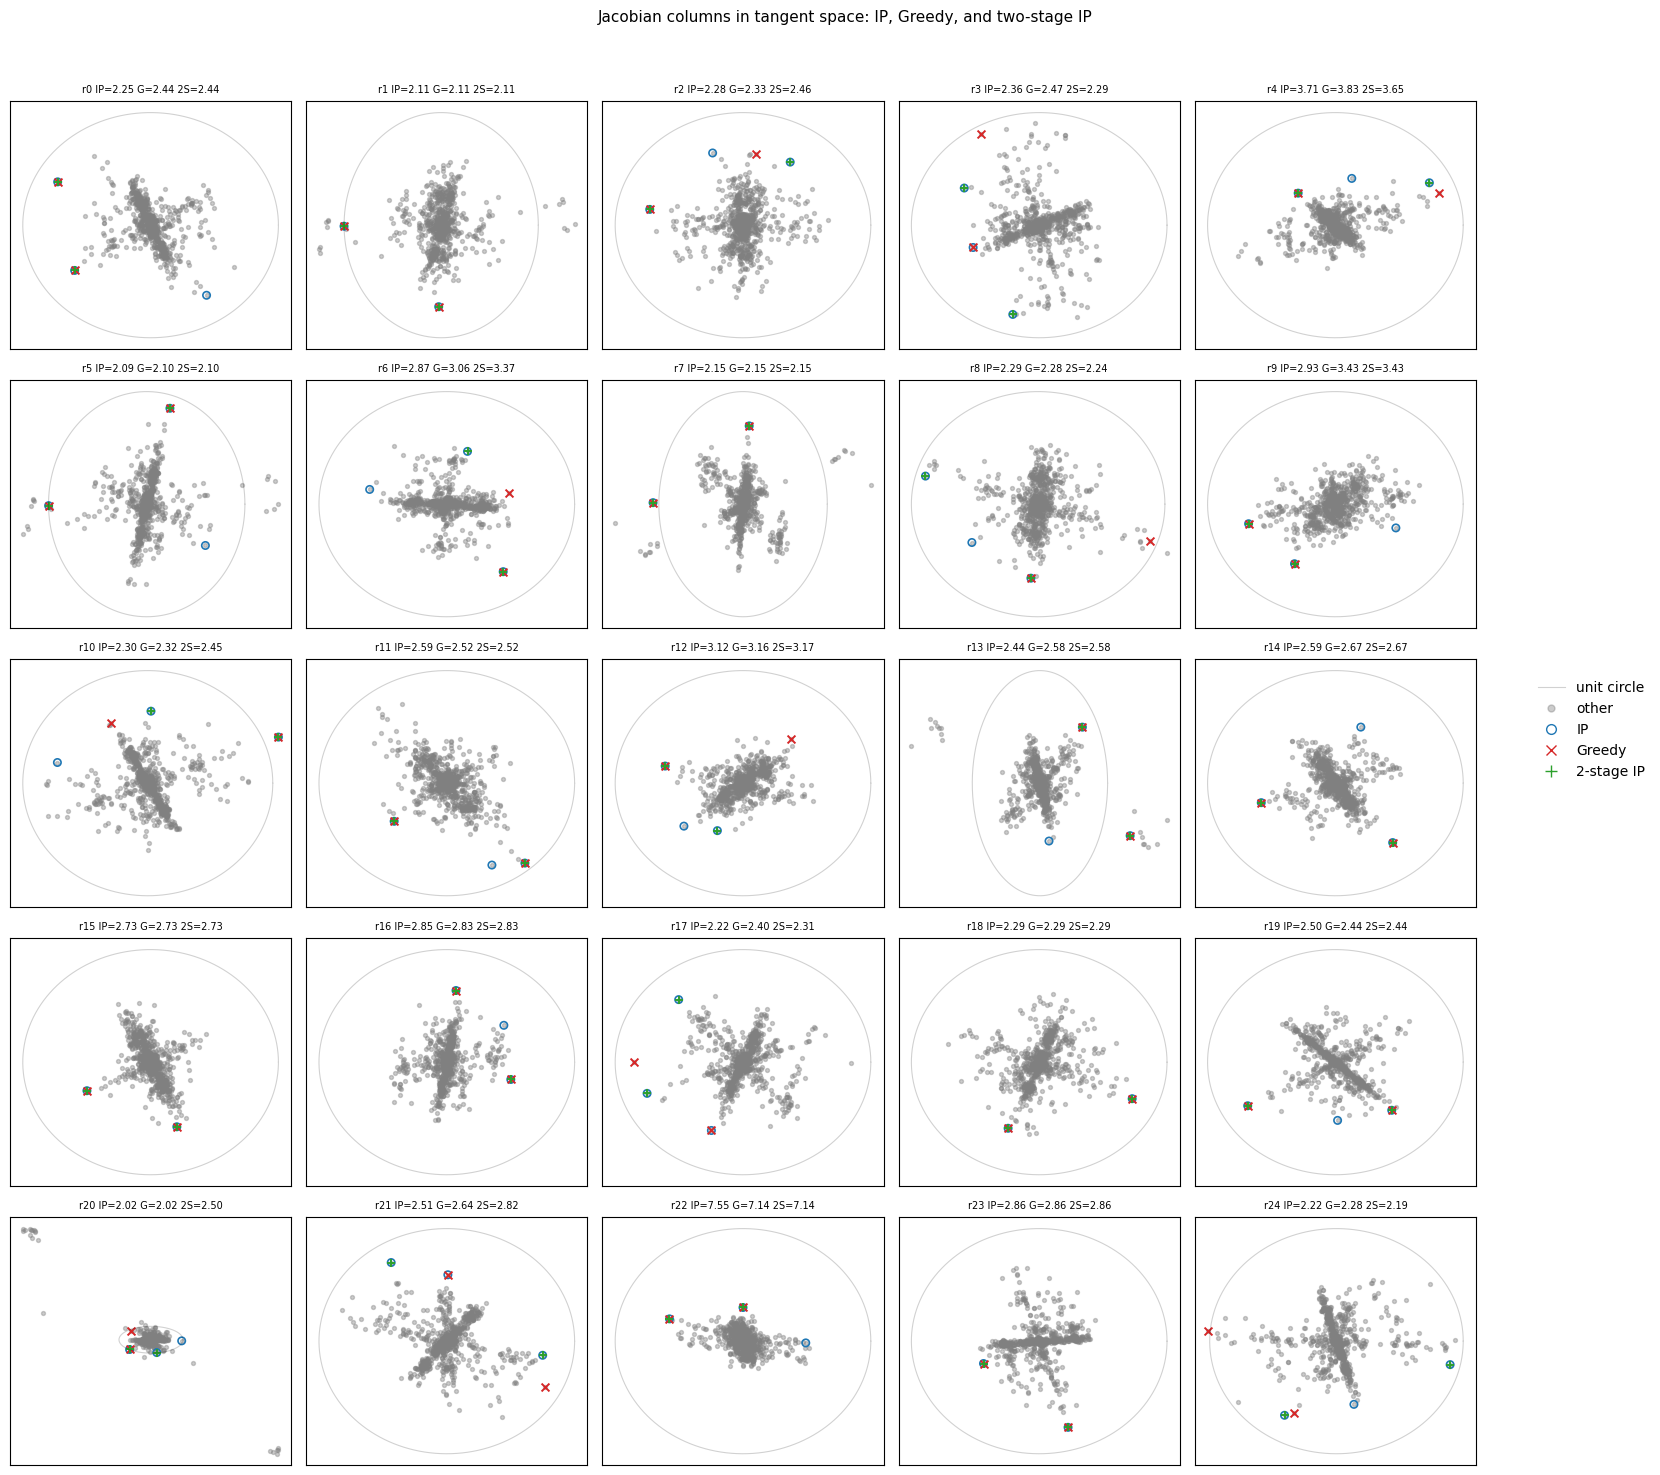

In [31]:
import numpy as np
import matplotlib.pyplot as plt

data_tensor = np.load('/Users/samsonkoelle/isometry-pursuit/data/ethanol_tensor.npy')  # (2, p, R)
R = data_tensor.shape[2]

ip_losses = replicates_df['group_lasso_norm'].values
greedy_losses = replicates_df['greedy_gl_norm'].values
two_stage_losses = replicates_df['greedy_gl_bp_norm'].values

ip_indices = replicates_df['basis_pursuit_indices'].tolist()
greedy_indices = replicates_df['greedy_gl_indices'].tolist()
two_stage_indices = replicates_df['greedy_gl_bp_indices'].tolist()

theta = np.linspace(0, 2 * np.pi, 300)
unit_x = np.cos(theta)
unit_y = np.sin(theta)

ncols = 5
nrows = (R + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols + 2, 3 * nrows))
axes = axes.flatten()

for i in range(R):
    ax = axes[i]
    cols = data_tensor[:, :, i]

    ax.plot(unit_x, unit_y, color='black', alpha=0.18, linewidth=0.8)

    ax.scatter(cols[0, :], cols[1, :], s=8, alpha=0.4, color='gray')

    ax.scatter(
        cols[0, ip_indices[i]],
        cols[1, ip_indices[i]],
        s=28,
        facecolors='none',
        edgecolors='tab:blue',
        linewidths=1.2,
    )

    ax.scatter(
        cols[0, greedy_indices[i]],
        cols[1, greedy_indices[i]],
        s=32,
        marker='x',
        color='tab:red',
        linewidths=1.4,
    )

    ax.scatter(
        cols[0, two_stage_indices[i]],
        cols[1, two_stage_indices[i]],
        s=36,
        marker='+',
        color='tab:green',
        linewidths=1.4,
    )

    ax.set_title(
        f"r{i} IP={ip_losses[i]:.2f} G={greedy_losses[i]:.2f} 2S={two_stage_losses[i]:.2f}",
        fontsize=7,
    )
    ax.set_xticks([])
    ax.set_yticks([])

for i in range(R, len(axes)):
    axes[i].set_visible(False)

legend_handles = [
    plt.Line2D([], [], color='black', alpha=0.18, linewidth=0.8, label='unit circle'),
    plt.Line2D([], [], marker='o', linestyle='None', color='gray',
               alpha=0.4, markersize=5, label='other'),
    plt.Line2D([], [], marker='o', linestyle='None', markerfacecolor='none',
               markeredgecolor='tab:blue', markersize=7, label='IP'),
    plt.Line2D([], [], marker='x', linestyle='None', color='tab:red',
               markersize=7, label='Greedy'),
    plt.Line2D([], [], marker='+', linestyle='None', color='tab:green',
               markersize=8, label='2-stage IP'),
]

fig.legend(
    handles=legend_handles,
    loc='center left',
    bbox_to_anchor=(0.90, 0.5),
    frameon=False,
)

plt.suptitle('Jacobian columns in tangent space: IP, Greedy, and two-stage IP', fontsize=11)
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from isometry_pursuit.algorithm import group_basis_pursuit, THRESHOLD
from isometry_pursuit.transformation import exponential_transformation
from isometry_pursuit.experiment import _gl_loss

# Choose Wine replicate.
data_tensor = np.load("/Users/samsonkoelle/isometry-pursuit/data/wine_standardized_resampled_tensor.npy")
replicate = 0

X = data_tensor[:, :, replicate]
X_t = exponential_transformation(X)

# Larger budgets than the standard experiment.
iteration_grid = [1_000, 5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 500_000]

rows = []
supports = []

for steps in iteration_grid:
    print(f"Running steps={steps}...")
    beta, iters, objective = group_basis_pursuit(
        X_t,
        steps=steps,
        constraint_violation=0.0,
    )

    row_norms = np.linalg.norm(beta, axis=1)
    support = np.where(row_norms > THRESHOLD)[0]
    supports.append(tuple(support.tolist()))

    residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
    support_loss = _gl_loss(X_t[:, support]) if len(support) >= X_t.shape[0] else np.inf

    rows.append({
        "steps_requested": steps,
        "iters_reported": iters,
        "objective": objective,
        "support_size": len(support),
        "residual_fro": residual,
        "support_pinv_loss": support_loss,
        "support": support.tolist(),
    })

probe = pd.DataFrame(rows)

probe["objective_delta"] = probe["objective"].diff()
probe["support_size_delta"] = probe["support_size"].diff()
probe["same_support_as_previous"] = [
    False if i == 0 else supports[i] == supports[i - 1]
    for i in range(len(supports))
]

display(probe[[
    "steps_requested",
    "iters_reported",
    "objective",
    "objective_delta",
    "support_size",
    "support_size_delta",
    "residual_fro",
    "support_pinv_loss",
    "same_support_as_previous",
]])
# os.chdir('?..')

Running steps=1000...
Running steps=5000...
Running steps=10000...
Running steps=25000...
Running steps=50000...
Running steps=100000...
Running steps=200000...
Running steps=500000...


/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/2851069754.py:35: RuntimeWarning: divide by zero encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/2851069754.py:35: RuntimeWarning: overflow encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/2851069754.py:35: RuntimeWarning: invalid value encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: divide by zero encountered in matmul
  res = matmul(transpose(vt), multiply(s[..., newaxis], transpose(u)))
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: overflow encoun

,steps_requested,iters_reported,objective,objective_delta,support_size,support_size_delta,residual_fro,support_pinv_loss,same_support_as_previous
0,1000,75,82.533134,NaN,28,NaN,9.390250e-07,83.749541,False
1,5000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
2,10000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
3,25000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
4,50000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
5,100000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
6,200000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
7,500000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True


In [33]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from isometry_pursuit.transformation import exponential_transformation
from isometry_pursuit.experiment import _gl_loss

RESULTS = {
    "Iris": "results/iris_results.json",
    "Wine": "results/wine_results.json",
    "Ethanol": "results/ethanol_results.json",
}

def load_results(name, path):
    with open(path) as f:
        out = json.load(f)

    meta = out["metadata"]
    D, P, R = meta["data_tensor_shape"]

    rows = []
    for rep in out["replicates"]:
        ip = rep["basis_pursuit_indices"]
        gf = rep["greedy_gl_indices"]
        gr = rep["greedy_gl_bp_indices"]

        rows.append({
            "dataset": name,
            "replicate": rep["replicate"],
            "D": D,
            "P": P,
            "R": R,
            "ip_support_size": rep["support_cardinality"],
            "ip_support": ip,
            "greedy_full_indices": gf,
            "greedy_restricted_indices": gr,
            "ip_support_loss": rep["group_lasso_norm"],
            "greedy_full_loss": rep["greedy_gl_norm"],
            "greedy_restricted_loss": rep["greedy_gl_bp_norm"],
            "bp_iterations": rep["basis_pursuit_iterations"],
            "full_greedy_better_than_restricted": rep["greedy_gl_norm"] < rep["greedy_gl_bp_norm"],
            "restricted_better_than_full_greedy": rep["greedy_gl_bp_norm"] < rep["greedy_gl_norm"],
            "restricted_better_than_ip_support": rep["greedy_gl_bp_norm"] < rep["group_lasso_norm"],
            "full_greedy_contained_in_ip": set(gf).issubset(set(ip)),
            "restricted_contained_in_ip": set(gr).issubset(set(ip)),
        })

    return pd.DataFrame(rows), meta

dfs = []
metadata = {}
for name, path in list(RESULTS.items())[1:2]:
    df_i, meta_i = load_results(name, path)
    # print(df_i.head())
    dfs.append(df_i)
    metadata[name] = meta_i

df = pd.concat(dfs, ignore_index=True)
df.head()

,dataset,replicate,D,P,R,ip_support_size,ip_support,greedy_full_indices,greedy_restricted_indices,ip_support_loss,greedy_full_loss,greedy_restricted_loss,bp_iterations,full_greedy_better_than_restricted,restricted_better_than_full_greedy,restricted_better_than_ip_support,full_greedy_contained_in_ip,restricted_contained_in_ip
0,Wine,0,13,89,25,28,"[0, 8, 9, 10, 18, 21, 22, 23, 25, 26, 27, 28, ...","[21, 72, 23, 26, 40, 35, 67, 10, 38, 8, 28, 55...","[21, 72, 23, 26, 40, 0, 10, 67, 38, 8, 30, 22,...",83.749541,102.703237,94.003299,100000,False,True,False,False,True
1,Wine,1,13,89,25,26,"[1, 9, 10, 11, 14, 17, 21, 24, 27, 34, 36, 37,...","[37, 86, 17, 76, 1, 21, 45, 69, 79, 36, 34, 14...","[37, 86, 17, 76, 1, 21, 45, 69, 79, 36, 34, 14...",80.206496,109.347381,109.734670,100000,True,False,False,False,True
2,Wine,2,13,89,25,25,"[1, 4, 6, 9, 18, 20, 22, 23, 27, 28, 29, 37, 4...","[6, 4, 72, 70, 65, 47, 27, 22, 37, 77, 55, 78,...","[6, 4, 72, 70, 65, 47, 27, 22, 37, 77, 55, 78,...",73.824135,93.084900,93.084900,100000,False,False,False,True,True
3,Wine,3,13,89,25,28,"[0, 2, 5, 7, 9, 13, 16, 27, 31, 34, 37, 39, 42...","[60, 2, 43, 73, 9, 72, 7, 42, 13, 54, 70, 15, 61]","[60, 2, 43, 73, 9, 72, 7, 42, 13, 54, 5, 75, 52]",76.463879,98.024397,101.790667,100000,True,False,False,False,True
4,Wine,4,13,89,25,24,"[4, 6, 7, 17, 18, 28, 31, 37, 41, 42, 43, 44, ...","[4, 60, 17, 71, 31, 64, 65, 6, 7, 68, 44, 28, 82]","[4, 60, 17, 71, 31, 64, 65, 6, 7, 68, 44, 28, 66]",76.424168,92.783952,95.612709,100000,True,False,False,False,True


In [16]:
from isometry_pursuit.loss import group_lasso_norm

glnorm = group_lasso_norm(result['beta'])


NameError: name 'result' is not defined

In [17]:
glnorm

NameError: name 'glnorm' is not defined

In [48]:
glnorm

2.1129039258663687

In [32]:
??isometry_pursuit

Signature:
isometry_pursuit(
    X,
    power=1.0,
    limit=1000000.0,
    max_steps=None,
    log_convergence=False,
    constraint_violation=0.0,
)
Docstring: <no docstring>
Source:   
def isometry_pursuit(
    X,
    power=1.0,
    limit=1e6,
    max_steps=None,
    log_convergence=False,
    constraint_violation=0.0,
):
    D, P = X.shape
    data_transformed = exponential_transformation(X, power=power)
    # Use CVXPY implementation
    beta, basis_pursuit_iterations, objective_value = group_basis_pursuit(
        data_transformed, constraint_violation=constraint_violation
    )
    # Note: Convergence logging is not implemented for the main experiment flow
    # since it would require calling group_basis_pursuit multiple times with different parameters
    # For convergence analysis, use the standalone convergence logging functions
    basis_pursuit_indices = np.where(np.linalg.norm(beta, axis=1) > THRESHOLD)[0]

    return {
        "beta": beta,
        "basis_pursuit_indices"

In [9]:
r = 1
X = data_tensor[:, :, r]  # (2, p)
p = X.shape[1]
print(f'Replicate {r}: p={p}, stored support={replicates_df.iloc[r]["support_cardinality"]}')
print()

factors = [1, 2, 4, 8, 16, 32]
for factor in factors:
    n_cols = p // factor
    col_idx = np.linspace(0, p - 1, n_cols, dtype=int)
    X_sub = X[:, col_idx]
    result = isometry_pursuit.algorithm.isometry_pursuit(X_sub)
    idx = result['basis_pursuit_indices']
    loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
    print(f'factor={factor:3d}  n_cols={n_cols:5d}  support={len(idx):5d}  loss={loss:.4f}')

Replicate 1: p=756, stored support=310



/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  1  n_cols=  756  support=  310  loss=88.3096


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  2  n_cols=  378  support=    2  loss=2.3395


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  4  n_cols=  189  support=    2  loss=2.4961


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  8  n_cols=   94  support=    2  loss=2.5168
factor= 16  n_cols=   47  support=    2  loss=3.0669
factor= 32  n_cols=   23  support=    3  loss=2.7349


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [11]:
import numpy as np
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.loss import isometry_loss

r = 1
X = data_tensor[:, :, r]
p = X.shape[1]
factors = [2]
n_random_reps = 10
rng = np.random.default_rng(42)

print(f"{'factor':>8} {'n_cols':>8} {'support_mean':>14} {'support_std':>12} {'loss_mean':>12} {'loss_std':>10}")
for factor in factors:
    n_cols = p // factor
    supports, losses = [], []
    for _ in range(n_random_reps):
        col_idx = rng.choice(p, size=n_cols, replace=False)
        X_sub = X[:, col_idx]
        result = isometry_pursuit(X_sub)
        idx = result['basis_pursuit_indices']
        loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
        supports.append(len(idx))
        losses.append(loss)
    print(f"{factor:>8} {n_cols:>8} {np.mean(supports):>14.1f} {np.std(supports):>12.1f} {np.mean(losses):>12.4f} {np.std(losses):>10.4f}")


  factor   n_cols   support_mean  support_std    loss_mean   loss_std


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

       2      378            2.2          0.4       2.1631     0.0804


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [12]:
losses

[2.349553473818398,
 2.1123366162604196,
 2.2250337405714653,
 2.1123366162604196,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.25886634916421]

In [7]:
import isometry_pursuit

In [2]:
import os
os.chdir('/Users/samsonkoelle')

In [16]:
import numpy as np
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.loss import isometry_loss

r = 1
X = data_tensor[:, :, r]
p = X.shape[1]  # 756
rng = np.random.default_rng(42)
n_random_reps = 1

sizes = [756]
# sizes = list(range(756, 328 - 1, -20))  # 756, 736, 716, ..., 336
results = []

for n_cols in sizes:
    for rep in range(n_random_reps):
        col_idx = rng.choice(p, size=n_cols, replace=False)
        X_sub = X[:, col_idx]
        res = isometry_pursuit(X_sub)
        idx = res['basis_pursuit_indices']
        loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
        results.append({'n_cols': n_cols, 'rep': rep, 'support': len(idx), 'loss': loss})
    print(f"n_cols={n_cols}  mean_support={np.mean([r['support'] for r in results if r['n_cols']==n_cols]):.1f}")


n_cols=756  mean_support=2.0


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(results)
grouped = df.groupby('n_cols')['support']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(grouped.mean().index, grouped.mean().values, 'o-')
ax.fill_between(grouped.mean().index,
                grouped.mean() - grouped.std(),
                grouped.mean() + grouped.std(), alpha=0.3)
ax.set_xlabel('n_cols (features)')
ax.set_ylabel('support cardinality')
ax.invert_xaxis()
plt.tight_layout()
plt.show()


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from isometry_pursuit.algorithm import group_basis_pursuit, THRESHOLD
from isometry_pursuit.transformation import exponential_transformation
from isometry_pursuit.experiment import _gl_loss

# Choose Wine replicate.
data_tensor = np.load("/Users/samsonkoelle/isometry-pursuit/data/wine_standardized_resampled_tensor.npy")
replicate = 0

X = data_tensor[:, :, replicate]
X_t = exponential_transformation(X)

# Larger budgets than the standard experiment.
iteration_grid = [1_000, 5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 500_000]

rows = []
supports = []

for steps in iteration_grid:
    print(f"Running steps={steps}...")
    beta, iters, objective = group_basis_pursuit(
        X_t,
        steps=steps,
        constraint_violation=0.0,
    )

    row_norms = np.linalg.norm(beta, axis=1)
    support = np.where(row_norms > THRESHOLD)[0]
    supports.append(tuple(support.tolist()))

    residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
    support_loss = _gl_loss(X_t[:, support]) if len(support) >= X_t.shape[0] else np.inf

    rows.append({
        "steps_requested": steps,
        "iters_reported": iters,
        "objective": objective,
        "support_size": len(support),
        "residual_fro": residual,
        "support_pinv_loss": support_loss,
        "support": support.tolist(),
    })

probe = pd.DataFrame(rows)

probe["objective_delta"] = probe["objective"].diff()
probe["support_size_delta"] = probe["support_size"].diff()
probe["same_support_as_previous"] = [
    False if i == 0 else supports[i] == supports[i - 1]
    for i in range(len(supports))
]

display(probe[[
    "steps_requested",
    "iters_reported",
    "objective",
    "objective_delta",
    "support_size",
    "support_size_delta",
    "residual_fro",
    "support_pinv_loss",
    "same_support_as_previous",
]])

Running steps=1000...
Running steps=5000...
Running steps=10000...
Running steps=25000...
Running steps=50000...
Running steps=100000...
Running steps=200000...
Running steps=500000...


/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/3019026306.py:34: RuntimeWarning: divide by zero encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/3019026306.py:34: RuntimeWarning: overflow encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/3019026306.py:34: RuntimeWarning: invalid value encountered in matmul
  residual = np.linalg.norm(X_t @ beta - np.eye(X_t.shape[0]), ord="fro")
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: divide by zero encountered in matmul
  res = matmul(transpose(vt), multiply(s[..., newaxis], transpose(u)))
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: overflow encoun

,steps_requested,iters_reported,objective,objective_delta,support_size,support_size_delta,residual_fro,support_pinv_loss,same_support_as_previous
0,1000,75,82.533134,NaN,28,NaN,9.390250e-07,83.749541,False
1,5000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
2,10000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
3,25000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
4,50000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
5,100000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
6,200000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True
7,500000,75,82.533134,0.0,28,0.0,9.390250e-07,83.749541,True


In [37]:
import cvxpy as cp
import numpy as np
import pandas as pd

from isometry_pursuit.algorithm import THRESHOLD
from isometry_pursuit.experiment import _gl_loss

def solve_bp_strict(X_t, max_iters=100_000, eps=1e-10):
    D, P = X_t.shape

    beta = cp.Variable((P, D))
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [X_t @ beta == np.eye(D)]

    problem = cp.Problem(objective, constraints)
    value = problem.solve(
        solver=cp.SCS,
        eps_abs=eps,
        eps_rel=eps,
        max_iters=max_iters,
        acceleration_lookback=0,
        adaptive_scale=False,
        verbose=False,
    )

    beta_value = beta.value.copy()
    beta_value[np.abs(beta_value) < 1e-6] = 0

    row_norms = np.linalg.norm(beta_value, axis=1)
    support = np.where(row_norms > THRESHOLD)[0]
    residual = np.linalg.norm(X_t @ beta_value - np.eye(D), ord="fro")

    return {
        "max_iters": max_iters,
        "eps": eps,
        "status": problem.status,
        "solver_value": value,
        "objective": np.sum(row_norms),
        "iters_reported": problem.solver_stats.num_iters,
        "support_size": len(support),
        "support": support.tolist(),
        "residual_fro": residual,
        "support_pinv_loss": _gl_loss(X_t[:, support]) if len(support) >= D else np.inf,
    }

In [38]:
rows = []

for eps in [1e-6, 1e-8, 1e-10, 1e-12, 1e-14]:
    print("eps", eps)
    rows.append(solve_bp_strict(X_t, max_iters=500_000, eps=eps))

strict_probe = pd.DataFrame(rows)
display(strict_probe[[
    "eps",
    "status",
    "iters_reported",
    "objective",
    "support_size",
    "residual_fro",
    "support_pinv_loss",
]])

eps 1e-06
eps 1e-08
eps 1e-10


/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/1567500538.py:31: RuntimeWarning: divide by zero encountered in matmul
  residual = np.linalg.norm(X_t @ beta_value - np.eye(D), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/1567500538.py:31: RuntimeWarning: overflow encountered in matmul
  residual = np.linalg.norm(X_t @ beta_value - np.eye(D), ord="fro")
/var/folders/qh/yqhypmrn2710qc_s67z4tyjr0000gn/T/ipykernel_86163/1567500538.py:31: RuntimeWarning: invalid value encountered in matmul
  residual = np.linalg.norm(X_t @ beta_value - np.eye(D), ord="fro")
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: divide by zero encountered in matmul
  res = matmul(transpose(vt), multiply(s[..., newaxis], transpose(u)))
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/numpy/linalg/linalg.py:2006: RuntimeWarning: overflow encountered in matmul

eps 1e-12
eps 1e-14


,eps,status,iters_reported,objective,support_size,residual_fro,support_pinv_loss
0,1.000000e-06,optimal,100,82.531771,28,3.108369e-06,83.749541
1,1.000000e-08,optimal,150,82.531764,28,1.362045e-08,83.749541
2,1.000000e-10,optimal_inaccurate,500000,82.531764,28,4.229373e-14,83.749541
3,1.000000e-12,optimal_inaccurate,500000,82.531764,28,4.229373e-14,83.749541
4,1.000000e-14,optimal_inaccurate,500000,82.531764,28,4.229373e-14,83.749541
